<a href="https://colab.research.google.com/github/trishnanika/Image-Processing-Project/blob/main/Image_Processing_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# CELL 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import tarfile
import shutil
import time
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# ============================================================
# CELL 2: CHECK FOR GPU
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
# ============================================================
# CELL 3: MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount("/content/drive")
print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


In [ ]:
# ============================================================
# CELL 4: DEFINE PROJECT PATH + CHECKPOINT DIRECTORY
# ============================================================

PROJECT_PATH = "/content/drive/MyDrive/CSE428_Project"

CHECKPOINT_DIR = os.path.join(PROJECT_PATH, "checkpoints_v2")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Project path:", PROJECT_PATH)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Project folder exists:", os.path.exists(PROJECT_PATH))

Project path: /content/drive/MyDrive/CSE428_Project
Checkpoint directory: /content/drive/MyDrive/CSE428_Project/checkpoints_v2
Project folder exists: True


In [ ]:
# ============================================================
# CELL 5: CLEAR OUT LEFTOVER PARTIAL/CORRUPTED LOCAL COPY
# ============================================================

LOCAL_DATA_PATH = "/content/oxford_pets_local"

if os.path.exists(LOCAL_DATA_PATH):
    print("Removing incomplete local copy from earlier interrupted transfer...")
    shutil.rmtree(LOCAL_DATA_PATH)
    print("Done. Local folder is now clean.")
else:
    print("No local folder found, nothing to clean.")

No local folder found, nothing to clean.


In [ ]:
# ============================================================
# CELL 6: COPY DATASET ARCHIVES TO LOCAL DISK (FAST)
# ============================================================

os.makedirs(LOCAL_DATA_PATH, exist_ok=True)

archive_files = ["images.tar.gz", "annotations.tar.gz"]

for fname in archive_files:
    src = os.path.join(PROJECT_PATH, fname)
    dst = os.path.join(LOCAL_DATA_PATH, fname)

    if not os.path.exists(dst):
        print(f"Copying {fname} ...")
        start = time.time()
        shutil.copy(src, dst)
        print(f"Done in {time.time() - start:.1f} seconds.")
    else:
        print(f"{fname} already exists locally, skipping.")

PROJECT_PATH = LOCAL_DATA_PATH
print("PROJECT_PATH is now:", PROJECT_PATH)

Copying images.tar.gz ...
Done in 18.1 seconds.
Copying annotations.tar.gz ...
Done in 0.6 seconds.
PROJECT_PATH is now: /content/oxford_pets_local


In [ ]:
# ============================================================
# CELL 7: EXTRACT DATASET LOCALLY
# ============================================================

images_tar = os.path.join(PROJECT_PATH, "images.tar.gz")
annotations_tar = os.path.join(PROJECT_PATH, "annotations.tar.gz")

images_dir = os.path.join(PROJECT_PATH, "images")
annotations_dir = os.path.join(PROJECT_PATH, "annotations")

if os.path.exists(images_dir):
    print("Images are already extracted.")
else:
    print("Extracting images...")
    with tarfile.open(images_tar, "r:gz") as tar:
        tar.extractall(PROJECT_PATH)
    print("Images extracted successfully!")

if os.path.exists(annotations_dir):
    print("Annotations are already extracted.")
else:
    print("Extracting annotations...")
    with tarfile.open(annotations_tar, "r:gz") as tar:
        tar.extractall(PROJECT_PATH)
    print("Annotations extracted successfully!")

masks_dir = os.path.join(annotations_dir, "trimaps")
print("Images dir:", images_dir)
print("Masks dir:", masks_dir)

Extracting images...


/tmp/ipykernel_1465/4098533348.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(PROJECT_PATH)


Images extracted successfully!
Extracting annotations...


/tmp/ipykernel_1465/4098533348.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(PROJECT_PATH)


Annotations extracted successfully!
Images dir: /content/oxford_pets_local/images
Masks dir: /content/oxford_pets_local/annotations/trimaps


In [ ]:
# ============================================================
# CELL 8: CREATE MATCHING IMAGE-MASK PAIRS
# ============================================================

image_paths = []
mask_paths = []

for image_name in sorted(os.listdir(images_dir)):
    if image_name.lower().endswith(".jpg"):
        base_name = os.path.splitext(image_name)[0]
        mask_name = base_name + ".png"

        image_path = os.path.join(images_dir, image_name)
        mask_path = os.path.join(masks_dir, mask_name)

        if os.path.exists(mask_path):
            image_paths.append(image_path)
            mask_paths.append(mask_path)

print("Number of matched image-mask pairs:", len(image_paths))

Number of matched image-mask pairs: 7390


In [ ]:
# ============================================================
# CELL 9: SET IMAGE SIZE AND BATCH SIZE
# ============================================================

IMG_SIZE = 128
BATCH_SIZE = 32

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 128
Batch size: 32


In [ ]:
# ============================================================
# CELL 10: TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_image_paths, temp_image_paths, train_mask_paths, temp_mask_paths = train_test_split(
    image_paths, mask_paths, test_size=0.3, random_state=42
)

val_image_paths, test_image_paths, val_mask_paths, test_mask_paths = train_test_split(
    temp_image_paths, temp_mask_paths, test_size=0.5, random_state=42
)

print("Train samples:", len(train_image_paths))
print("Validation samples:", len(val_image_paths))
print("Test samples:", len(test_image_paths))

Train samples: 5173
Validation samples: 1108
Test samples: 1109


In [ ]:
# ============================================================
# CELL 11: EXTRACT BREED NAMES FROM FILENAMES
# ============================================================

def get_breed_name(image_path):
    filename = os.path.splitext(os.path.basename(image_path))[0]
    breed_name = filename.rsplit("_", 1)[0]
    return breed_name

for path in train_image_paths[:5]:
    print(os.path.basename(path), "→", get_breed_name(path))

yorkshire_terrier_101.jpg → yorkshire_terrier
saint_bernard_117.jpg → saint_bernard
miniature_pinscher_174.jpg → miniature_pinscher
Sphynx_4.jpg → Sphynx
beagle_130.jpg → beagle


In [ ]:
# ============================================================
# CELL 12: CREATE BREED → CLASS INDEX MAPPING
# ============================================================

all_breeds = sorted(set(get_breed_name(path) for path in image_paths))

breed_to_idx = {breed: index for index, breed in enumerate(all_breeds)}
idx_to_breed = {index: breed for breed, index in breed_to_idx.items()}

print("Number of breeds:", len(all_breeds))

Number of breeds: 37


In [ ]:
# ============================================================
# CELL 13: DICE LOSS (FOR BINARY SEGMENTATION)
# ============================================================

class DiceLoss(nn.Module):
    """
    Dice Loss for binary segmentation.
    Expects:
        logits: (B, 1, H, W) raw model output (before sigmoid)
        targets: (B, H, W) or (B, 1, H, W) binary ground truth (0/1)
    """

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)

        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1).float()

        intersection = (probs * targets).sum(dim=1)
        union = probs.sum(dim=1) + targets.sum(dim=1)

        dice_score = (2.0 * intersection + self.smooth) / (union + self.smooth)
        dice_loss = 1.0 - dice_score

        return dice_loss.mean()

print("Dice Loss defined successfully.")

Dice Loss defined successfully.


In [ ]:
# ============================================================
# CELL 14: CREATE MULTI-TASK DATASET (BINARY MASK)
# ============================================================

import random as pyrandom

class PetMultiTaskDataset(Dataset):

    def __init__(self, image_paths, mask_paths, breed_to_idx, img_size=256, augment=False):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.breed_to_idx = breed_to_idx
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")
        raw_mask = np.array(Image.open(self.mask_paths[index]))

        # Boundary pixels (value 3) folded into foreground (matches your earlier approach)
        mask = (raw_mask != 2).astype(np.uint8)

        image = image.resize((self.img_size, self.img_size), Image.Resampling.BILINEAR)
        mask = Image.fromarray(mask).resize((self.img_size, self.img_size), Image.Resampling.NEAREST)

        if self.augment:
            if pyrandom.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)
            if pyrandom.random() < 0.3:
                angle = pyrandom.uniform(-15, 15)
                image = TF.rotate(image, angle, interpolation=TF.InterpolationMode.BILINEAR)
                mask = TF.rotate(mask, angle, interpolation=TF.InterpolationMode.NEAREST)
            if pyrandom.random() < 0.3:
                image = TF.adjust_brightness(image, pyrandom.uniform(0.8, 1.2))
                image = TF.adjust_contrast(image, pyrandom.uniform(0.8, 1.2))

        image = np.array(image)
        mask = np.array(mask)

        image = torch.tensor(image, dtype=torch.float32).permute(2, 0, 1) / 255.0
        mask = torch.tensor(mask, dtype=torch.float32)   # float, ready for Dice/BCE

        breed = get_breed_name(self.image_paths[index])
        label = torch.tensor(self.breed_to_idx[breed], dtype=torch.long)

        return image, mask, label

print("Multi-task dataset class created successfully.")

Multi-task dataset class created successfully.


In [ ]:
# ============================================================
# CELL 15: CREATE MULTI-TASK DATASET OBJECTS
# ============================================================

train_multitask_dataset = PetMultiTaskDataset(train_image_paths, train_mask_paths, breed_to_idx, img_size=IMG_SIZE, augment=True)
val_multitask_dataset = PetMultiTaskDataset(val_image_paths, val_mask_paths, breed_to_idx, img_size=IMG_SIZE, augment=False)
test_multitask_dataset = PetMultiTaskDataset(test_image_paths, test_mask_paths, breed_to_idx, img_size=IMG_SIZE, augment=False)

print("Training samples:", len(train_multitask_dataset))
print("Validation samples:", len(val_multitask_dataset))
print("Test samples:", len(test_multitask_dataset))

Training samples: 5173
Validation samples: 1108
Test samples: 1109


In [ ]:
# ============================================================
# CELL 16: CREATE MULTI-TASK DATA LOADERS
# ============================================================

train_multitask_loader = DataLoader(train_multitask_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_multitask_loader = DataLoader(val_multitask_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_multitask_loader = DataLoader(test_multitask_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print("Training batches:", len(train_multitask_loader))
print("Validation batches:", len(val_multitask_loader))
print("Test batches:", len(test_multitask_loader))

Training batches: 162
Validation batches: 35
Test batches: 35


In [ ]:
# ============================================================
# CELL 17: CHECK ONE MULTI-TASK BATCH
# ============================================================

images, masks, labels = next(iter(train_multitask_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)
print("Labels shape:", labels.shape)
print("Mask unique values:", torch.unique(masks))
print("Label range:", labels.min().item(), "to", labels.max().item())

Images shape: torch.Size([32, 3, 128, 128])
Masks shape: torch.Size([32, 128, 128])
Labels shape: torch.Size([32])
Mask unique values: tensor([0., 1.])
Label range: 0 to 34


In [ ]:
# ============================================================
# CELL 18: U-NET DOUBLE CONVOLUTION BLOCK
# ============================================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

print("DoubleConv block defined.")

DoubleConv block defined.


In [ ]:
# ============================================================
# CELL 19: CLASSIFIER HEAD WITH EXTRA CONV LAYERS
# ============================================================

class ClassifierHeadV2(nn.Module):
    """
    Adds 2 convolutional layers on the bottleneck feature map
    BEFORE global average pooling, to let the classifier learn
    its own spatial features rather than relying purely on the
    segmentation-shared bottleneck.
    """

    def __init__(self, in_channels=1024, num_classes=37):
        super().__init__()

        # Extra convolutional layers before pooling
        self.conv1 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(in_channels)

        self.conv2 = nn.Conv2d(in_channels, 512, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(512)

        self.relu = nn.ReLU(inplace=True)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.fc1 = nn.Linear(512, 256)
        self.bn_fc1 = nn.BatchNorm1d(256)
        self.dropout = nn.Dropout(p=0.4)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):

        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))

        x = self.global_pool(x)
        x = torch.flatten(x, 1)

        x = self.fc1(x)
        x = self.bn_fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

print("ClassifierHeadV2 (with extra conv layers) defined.")

ClassifierHeadV2 (with extra conv layers) defined.


In [ ]:
# ============================================================
# CELL 20: VERIFY CLASSIFIER HEAD SHAPE
# ============================================================

test_head = ClassifierHeadV2(in_channels=1024, num_classes=37).to(device)
dummy_input = torch.randn(4, 1024, 16, 16).to(device)  # matches 256/16 bottleneck spatial size

test_head.eval()
with torch.no_grad():
    output = test_head(dummy_input)

print("Classifier output shape:", output.shape)  # should be [4, 37]

Classifier output shape: torch.Size([4, 37])


In [ ]:
# ============================================================
# CELL 21: BASE MULTI-TASK U-NET (BINARY SEGMENTATION HEAD)
# ============================================================

class MultiTaskUNet(nn.Module):

    def __init__(self, num_breed_classes=37):
        super().__init__()

        # ---- Encoder ----
        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(kernel_size=2)

        # ---- Bottleneck ----
        self.bottleneck = DoubleConv(512, 1024)

        # ---- Classification head ----
        self.classifier = ClassifierHeadV2(in_channels=1024, num_classes=num_breed_classes)

        # ---- Decoder ----
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        # ---- Segmentation output: single channel (binary) ----
        self.final = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        classification_output = self.classifier(b)

        d4 = self.up4(b); d4 = torch.cat([d4, e4], dim=1); d4 = self.dec4(d4)
        d3 = self.up3(d4); d3 = torch.cat([d3, e3], dim=1); d3 = self.dec3(d3)
        d2 = self.up2(d3); d2 = torch.cat([d2, e2], dim=1); d2 = self.dec2(d2)
        d1 = self.up1(d2); d1 = torch.cat([d1, e1], dim=1); d1 = self.dec1(d1)

        # Output shape: (B, 1, H, W) -> squeeze to (B, H, W)
        segmentation_output = self.final(d1).squeeze(1)

        return segmentation_output, classification_output

print("Base Multi-Task U-Net (1-channel segmentation output) defined.")

Base Multi-Task U-Net (1-channel segmentation output) defined.


In [ ]:
# ============================================================
# CELL 22: CREATE AND VERIFY BASE MODEL
# ============================================================

multitask_model = MultiTaskUNet(num_breed_classes=37).to(device)

images, masks, labels = next(iter(train_multitask_loader))
images = images.to(device)

multitask_model.eval()
with torch.no_grad():
    seg_out, cls_out = multitask_model(images)

print("Input shape:", images.shape)
print("Segmentation output shape:", seg_out.shape)   # should be [32, 128, 128]
print("Classification output shape:", cls_out.shape) # should be [32, 37]

total_params = sum(p.numel() for p in multitask_model.parameters() if p.requires_grad)
print("Trainable parameters:", total_params)

Input shape: torch.Size([32, 3, 128, 128])
Segmentation output shape: torch.Size([32, 128, 128])
Classification output shape: torch.Size([32, 37])
Trainable parameters: 45345254


In [ ]:
# ============================================================
# CELL 23: MEMORY STRESS TEST (CONFIRM BATCH/IMAGE SIZE FITS)
# ============================================================

try:
    test_batch = torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE).to(device)

    multitask_model.train()
    seg_out, cls_out = multitask_model(test_batch)

    dummy_mask = torch.randint(0, 2, (BATCH_SIZE, IMG_SIZE, IMG_SIZE)).float().to(device)
    dummy_labels = torch.randint(0, 37, (BATCH_SIZE,)).to(device)

    dice_loss_fn = DiceLoss()
    seg_loss = dice_loss_fn(seg_out, dummy_mask)
    cls_loss = nn.CrossEntropyLoss()(cls_out, dummy_labels)
    loss = seg_loss + cls_loss
    loss.backward()

    print("✓ Forward + backward pass succeeded at this batch/image size.")
    print(f"GPU memory used: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

    multitask_model.zero_grad()
    del test_batch, seg_out, cls_out, dummy_mask, dummy_labels
    torch.cuda.empty_cache()

except torch.cuda.OutOfMemoryError:
    print("✗ OUT OF MEMORY. Reduce BATCH_SIZE or IMG_SIZE before proceeding.")
    torch.cuda.empty_cache()

✓ Forward + backward pass succeeded at this batch/image size.
GPU memory used: 0.46 GB


In [ ]:
# ============================================================
# CELL 24: ATTENTION GATE MODULE
# ============================================================

class AttentionGate(nn.Module):

    def __init__(self, F_g, F_l, F_int):
        super().__init__()

        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        attention = self.relu(g1 + x1)
        attention = self.psi(attention)
        return x * attention

print("Attention Gate module defined.")

Attention Gate module defined.


In [ ]:
# ============================================================
# CELL 25: ATTENTION MULTI-TASK U-NET
# ============================================================

class AttentionMultiTaskUNet(nn.Module):

    def __init__(self, num_breed_classes=37):
        super().__init__()

        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(kernel_size=2)

        self.bottleneck = DoubleConv(512, 1024)

        self.classifier = ClassifierHeadV2(in_channels=1024, num_classes=num_breed_classes)

        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.att4 = AttentionGate(F_g=512, F_l=512, F_int=256)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.att3 = AttentionGate(F_g=256, F_l=256, F_int=128)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.att2 = AttentionGate(F_g=128, F_l=128, F_int=64)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.att1 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.dec1 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        classification_output = self.classifier(b)

        d4 = self.up4(b); e4a = self.att4(g=d4, x=e4); d4 = torch.cat([d4, e4a], dim=1); d4 = self.dec4(d4)
        d3 = self.up3(d4); e3a = self.att3(g=d3, x=e3); d3 = torch.cat([d3, e3a], dim=1); d3 = self.dec3(d3)
        d2 = self.up2(d3); e2a = self.att2(g=d2, x=e2); d2 = torch.cat([d2, e2a], dim=1); d2 = self.dec2(d2)
        d1 = self.up1(d2); e1a = self.att1(g=d1, x=e1); d1 = torch.cat([d1, e1a], dim=1); d1 = self.dec1(d1)

        segmentation_output = self.final(d1).squeeze(1)

        return segmentation_output, classification_output

print("Attention Multi-Task U-Net (1-channel segmentation output) defined.")

Attention Multi-Task U-Net (1-channel segmentation output) defined.


In [ ]:
# ============================================================
# CELL 26: CREATE AND VERIFY ATTENTION MODEL
# ============================================================

attention_model = AttentionMultiTaskUNet(num_breed_classes=37).to(device)

attention_model.eval()
with torch.no_grad():
    seg_out, cls_out = attention_model(images)

print("Segmentation output shape:", seg_out.shape)
print("Classification output shape:", cls_out.shape)

total_params = sum(p.numel() for p in attention_model.parameters() if p.requires_grad)
print("Trainable parameters:", total_params)

Segmentation output shape: torch.Size([32, 128, 128])
Classification output shape: torch.Size([32, 37])
Trainable parameters: 45696786


In [ ]:
# ============================================================
# CELL 27: TRAIN / VALIDATE FUNCTIONS (DICE + CROSS-ENTROPY)
# ============================================================

def train_one_epoch(model, loader, optimizer, seg_criterion, cls_criterion, device,
                     seg_weight=1.0, cls_weight=1.0):

    model.train()
    running_loss, running_seg_loss, running_cls_loss = 0.0, 0.0, 0.0

    for images, masks, labels in loader:
        images, masks, labels = images.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_output, cls_output = model(images)

        seg_loss = seg_criterion(seg_output, masks)
        cls_loss = cls_criterion(cls_output, labels)
        loss = seg_weight * seg_loss + cls_weight * cls_loss

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        running_seg_loss += seg_loss.item()
        running_cls_loss += cls_loss.item()

    n = len(loader)
    return running_loss / n, running_seg_loss / n, running_cls_loss / n


def validate_one_epoch(model, loader, seg_criterion, cls_criterion, device,
                        seg_weight=1.0, cls_weight=1.0):

    model.eval()
    running_loss, running_seg_loss, running_cls_loss = 0.0, 0.0, 0.0

    with torch.no_grad():
        for images, masks, labels in loader:
            images, masks, labels = images.to(device), masks.to(device), labels.to(device)

            seg_output, cls_output = model(images)

            seg_loss = seg_criterion(seg_output, masks)
            cls_loss = cls_criterion(cls_output, labels)
            loss = seg_weight * seg_loss + cls_weight * cls_loss

            running_loss += loss.item()
            running_seg_loss += seg_loss.item()
            running_cls_loss += cls_loss.item()

    n = len(loader)
    return running_loss / n, running_seg_loss / n, running_cls_loss / n

print("Train/validate functions defined.")

Train/validate functions defined.


In [ ]:
# ============================================================
# CELL 28: CHECKPOINT SAVE/LOAD HELPERS (DRIVE-BACKED)
# ============================================================

def save_resume_checkpoint(model, optimizer, epoch, history, path):
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history
    }, path)


def load_resume_checkpoint(model, optimizer, path, device):
    checkpoint = torch.load(path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    return checkpoint["epoch"], checkpoint["history"]

print("Checkpoint helper functions defined.")

Checkpoint helper functions defined.


In [ ]:
# ============================================================
# CELL 29: BASE MODEL TRAINING CONFIGURATION
# ============================================================

multitask_model = MultiTaskUNet(num_breed_classes=37).to(device)

optimizer = optim.Adam(multitask_model.parameters(), lr=0.001, weight_decay=1e-4)

segmentation_criterion = DiceLoss()
classification_criterion = nn.CrossEntropyLoss()

SEGMENTATION_WEIGHT = 1.0
CLASSIFICATION_WEIGHT = 1.5
NUM_EPOCHS = 60

best_val_loss = float("inf")
train_losses, val_losses = [], []
train_seg_losses, val_seg_losses = [], []
train_cls_losses, val_cls_losses = [], []

BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "best_base_multitask_unet.pth")
RESUME_PATH = os.path.join(CHECKPOINT_DIR, "resume_base_multitask_unet.pth")

print("========== BASE MODEL SETTINGS ==========")
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMG_SIZE)
print("Segmentation loss: Dice Loss")
print("Classification loss: CrossEntropyLoss")
print("Segmentation weight:", SEGMENTATION_WEIGHT)
print("Classification weight:", CLASSIFICATION_WEIGHT)
print("Best model path:", BEST_MODEL_PATH)
print("==========================================")

========== BASE MODEL SETTINGS ==========
Epochs: 60
Batch size: 32
Image size: 128
Segmentation loss: Dice Loss
Classification loss: CrossEntropyLoss
Segmentation weight: 1.0
Classification weight: 1.5
Best model path: /content/drive/MyDrive/CSE428_Project/checkpoints_v2/best_base_multitask_unet.pth


In [ ]:
# ============================================================
# CELL 30: TRAIN BASE MULTI-TASK U-NET (RESUMABLE, 60 EPOCHS)
# ============================================================

start_epoch = 0

if os.path.exists(RESUME_PATH):
    print("Resume checkpoint found — resuming training...")
    start_epoch, history = load_resume_checkpoint(multitask_model, optimizer, RESUME_PATH, device)
    train_losses = history["train_losses"]
    val_losses = history["val_losses"]
    train_seg_losses = history["train_seg_losses"]
    val_seg_losses = history["val_seg_losses"]
    train_cls_losses = history["train_cls_losses"]
    val_cls_losses = history["val_cls_losses"]
    best_val_loss = min(val_losses) if val_losses else float("inf")
    print(f"Resuming from epoch {start_epoch + 1}")
else:
    print("No resume checkpoint found — starting fresh.")

for epoch in range(start_epoch, NUM_EPOCHS):

    print(f"\nEpoch [{epoch + 1}/{NUM_EPOCHS}]")

    train_loss, train_seg_loss, train_cls_loss = train_one_epoch(
        multitask_model, train_multitask_loader, optimizer,
        segmentation_criterion, classification_criterion, device,
        seg_weight=SEGMENTATION_WEIGHT, cls_weight=CLASSIFICATION_WEIGHT
    )

    val_loss, val_seg_loss, val_cls_loss = validate_one_epoch(
        multitask_model, val_multitask_loader,
        segmentation_criterion, classification_criterion, device,
        seg_weight=SEGMENTATION_WEIGHT, cls_weight=CLASSIFICATION_WEIGHT
    )

    train_losses.append(train_loss); val_losses.append(val_loss)
    train_seg_losses.append(train_seg_loss); val_seg_losses.append(val_seg_loss)
    train_cls_losses.append(train_cls_loss); val_cls_losses.append(val_cls_loss)

    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
    print(f"Train Seg (Dice) Loss: {train_seg_loss:.4f} | Val Seg Loss: {val_seg_loss:.4f}")
    print(f"Train Cls Loss: {train_cls_loss:.4f} | Val Cls Loss: {val_cls_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(multitask_model.state_dict(), BEST_MODEL_PATH)
        print("✓ Best model saved to Drive.")

    history = {
        "train_losses": train_losses, "val_losses": val_losses,
        "train_seg_losses": train_seg_losses, "val_seg_losses": val_seg_losses,
        "train_cls_losses": train_cls_losses, "val_cls_losses": val_cls_losses
    }
    save_resume_checkpoint(multitask_model, optimizer, epoch + 1, history, RESUME_PATH)

print("\nTraining complete!")

Resume checkpoint found — resuming training...
Resuming from epoch 42

Epoch [42/60]
Train Loss: 0.9683 | Val Loss: 2.5975
Train Seg (Dice) Loss: 0.1059 | Val Seg Loss: 0.1213
Train Cls Loss: 0.5749 | Val Cls Loss: 1.6508

Epoch [43/60]
Train Loss: 0.9641 | Val Loss: 2.2838
Train Seg (Dice) Loss: 0.1061 | Val Seg Loss: 0.1203
Train Cls Loss: 0.5719 | Val Cls Loss: 1.4424

Epoch [44/60]
Train Loss: 0.9007 | Val Loss: 2.2719
Train Seg (Dice) Loss: 0.1056 | Val Seg Loss: 0.1091
Train Cls Loss: 0.5300 | Val Cls Loss: 1.4419

Epoch [45/60]
Train Loss: 0.8155 | Val Loss: 2.5839
Train Seg (Dice) Loss: 0.1047 | Val Seg Loss: 0.1125
Train Cls Loss: 0.4739 | Val Cls Loss: 1.6476

Epoch [46/60]
Train Loss: 0.8424 | Val Loss: 2.3218
Train Seg (Dice) Loss: 0.1051 | Val Seg Loss: 0.1095
Train Cls Loss: 0.4915 | Val Cls Loss: 1.4748

Epoch [47/60]
Train Loss: 0.7405 | Val Loss: 2.4545
Train Seg (Dice) Loss: 0.1041 | Val Seg Loss: 0.1090
Train Cls Loss: 0.4243 | Val Cls Loss: 1.5637

Epoch [48/60]
Tra

Good progress — training completed. One honest flag before moving on: look at the gap between Train Cls Loss (0.37) and Val Cls Loss (1.23) — that's a meaningful sign of overfitting on the classification side (train loss dropping much faster than validation). Segmentation is fine (0.1003 vs 0.1087, very close). This is worth mentioning in your presentation as an observed trade-off — classification head is more prone to overfitting than the segmentation decoder in your setup, likely because it has fewer effective "views" of variation per class relative to the shared encoder's capacity, even with augmentation on. Not something to necessarily fix now, but good to be able to explain if asked in viva.

In [ ]:
# ============================================================
# CELL 31: ATTENTION MODEL TRAINING CONFIGURATION
# ============================================================

attention_model = AttentionMultiTaskUNet(num_breed_classes=37).to(device)

attention_optimizer = optim.Adam(attention_model.parameters(), lr=0.001, weight_decay=1e-4)

attention_segmentation_criterion = DiceLoss()
attention_classification_criterion = nn.CrossEntropyLoss()

attention_best_val_loss = float("inf")
attention_train_losses, attention_val_losses = [], []
attention_train_seg_losses, attention_val_seg_losses = [], []
attention_train_cls_losses, attention_val_cls_losses = [], []

ATTENTION_BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "best_attention_multitask_unet.pth")
ATTENTION_RESUME_PATH = os.path.join(CHECKPOINT_DIR, "resume_attention_multitask_unet.pth")

print("========== ATTENTION MODEL SETTINGS ==========")
print("Epochs:", NUM_EPOCHS)
print("Segmentation loss: Dice Loss")
print("Classification loss: CrossEntropyLoss")
print("Best model path:", ATTENTION_BEST_MODEL_PATH)
print("================================================")

========== ATTENTION MODEL SETTINGS ==========
Epochs: 60
Segmentation loss: Dice Loss
Classification loss: CrossEntropyLoss
Best model path: /content/drive/MyDrive/CSE428_Project/checkpoints_v2/best_attention_multitask_unet.pth


In [ ]:
# ============================================================
# CELL 32: TRAIN ATTENTION MULTI-TASK U-NET (RESUMABLE, 60 EPOCHS)
# ============================================================

attention_start_epoch = 0

if os.path.exists(ATTENTION_RESUME_PATH):
    print("Resume checkpoint found — resuming attention training...")
    attention_start_epoch, history = load_resume_checkpoint(attention_model, attention_optimizer, ATTENTION_RESUME_PATH, device)
    attention_train_losses = history["train_losses"]
    attention_val_losses = history["val_losses"]
    attention_train_seg_losses = history["train_seg_losses"]
    attention_val_seg_losses = history["val_seg_losses"]
    attention_train_cls_losses = history["train_cls_losses"]
    attention_val_cls_losses = history["val_cls_losses"]
    attention_best_val_loss = min(attention_val_losses) if attention_val_losses else float("inf")
    print(f"Resuming from epoch {attention_start_epoch + 1}")
else:
    print("No resume checkpoint found — starting fresh.")

for epoch in range(attention_start_epoch, NUM_EPOCHS):

    print(f"\nEpoch [{epoch + 1}/{NUM_EPOCHS}]")

    train_loss, train_seg_loss, train_cls_loss = train_one_epoch(
        attention_model, train_multitask_loader, attention_optimizer,
        attention_segmentation_criterion, attention_classification_criterion, device,
        seg_weight=SEGMENTATION_WEIGHT, cls_weight=CLASSIFICATION_WEIGHT
    )

    val_loss, val_seg_loss, val_cls_loss = validate_one_epoch(
        attention_model, val_multitask_loader,
        attention_segmentation_criterion, attention_classification_criterion, device,
        seg_weight=SEGMENTATION_WEIGHT, cls_weight=CLASSIFICATION_WEIGHT
    )

    attention_train_losses.append(train_loss); attention_val_losses.append(val_loss)
    attention_train_seg_losses.append(train_seg_loss); attention_val_seg_losses.append(val_seg_loss)
    attention_train_cls_losses.append(train_cls_loss); attention_val_cls_losses.append(val_cls_loss)

    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
    print(f"Train Seg (Dice) Loss: {train_seg_loss:.4f} | Val Seg Loss: {val_seg_loss:.4f}")
    print(f"Train Cls Loss: {train_cls_loss:.4f} | Val Cls Loss: {val_cls_loss:.4f}")

    if val_loss < attention_best_val_loss:
        attention_best_val_loss = val_loss
        torch.save(attention_model.state_dict(), ATTENTION_BEST_MODEL_PATH)
        print("✓ Best attention model saved to Drive.")

    history = {
        "train_losses": attention_train_losses, "val_losses": attention_val_losses,
        "train_seg_losses": attention_train_seg_losses, "val_seg_losses": attention_val_seg_losses,
        "train_cls_losses": attention_train_cls_losses, "val_cls_losses": attention_val_cls_losses
    }
    save_resume_checkpoint(attention_model, attention_optimizer, epoch + 1, history, ATTENTION_RESUME_PATH)

print("\nAttention model training complete!")

No resume checkpoint found — starting fresh.

Epoch [1/60]
Train Loss: 5.7113 | Val Loss: 5.7560
Train Seg (Dice) Loss: 0.2952 | Val Seg Loss: 0.2884
Train Cls Loss: 3.6107 | Val Cls Loss: 3.6451
✓ Best attention model saved to Drive.

Epoch [2/60]
Train Loss: 5.3481 | Val Loss: 5.4635
Train Seg (Dice) Loss: 0.2433 | Val Seg Loss: 0.2323
Train Cls Loss: 3.4032 | Val Cls Loss: 3.4875
✓ Best attention model saved to Drive.

Epoch [3/60]
Train Loss: 5.0275 | Val Loss: 5.5519
Train Seg (Dice) Loss: 0.2221 | Val Seg Loss: 0.2408
Train Cls Loss: 3.2036 | Val Cls Loss: 3.5407

Epoch [4/60]
Train Loss: 4.8292 | Val Loss: 5.3060
Train Seg (Dice) Loss: 0.2017 | Val Seg Loss: 0.2448
Train Cls Loss: 3.0850 | Val Cls Loss: 3.3741
✓ Best attention model saved to Drive.

Epoch [5/60]
Train Loss: 4.6879 | Val Loss: 5.4274
Train Seg (Dice) Loss: 0.1979 | Val Seg Loss: 0.2692
Train Cls Loss: 2.9933 | Val Cls Loss: 3.4388

Epoch [6/60]
Train Loss: 4.4083 | Val Loss: 4.4751
Train Seg (Dice) Loss: 0.1865 |

In [ ]:
# ============================================================
# CELL 33: EVALUATION FUNCTION (SINGLE-CHANNEL SIGMOID OUTPUT)
# ============================================================

def evaluate_multitask_model(model, loader, device, split_name="Test", threshold=0.5):

    model.eval()

    seg_correct_pixels = 0
    seg_total_pixels = 0
    seg_confusion = torch.zeros(2, 2, dtype=torch.long)

    all_true_labels = []
    all_pred_labels = []

    with torch.no_grad():
        for images, masks, labels in loader:

            images, masks, labels = images.to(device), masks.to(device), labels.to(device)

            seg_output, cls_output = model(images)  # seg_output shape: (B, H, W), raw logits

            probs = torch.sigmoid(seg_output)
            predicted_masks = (probs > threshold).long()
            masks_long = masks.long()

            seg_correct_pixels += (predicted_masks == masks_long).sum().item()
            seg_total_pixels += masks_long.numel()

            true_flat = masks_long.view(-1).cpu()
            pred_flat = predicted_masks.view(-1).cpu()
            combined = true_flat * 2 + pred_flat
            batch_confusion = torch.bincount(combined, minlength=4).reshape(2, 2)
            seg_confusion += batch_confusion

            predicted_labels = torch.argmax(cls_output, dim=1)
            all_true_labels.extend(labels.cpu().numpy())
            all_pred_labels.extend(predicted_labels.cpu().numpy())

    pixel_accuracy = seg_correct_pixels / seg_total_pixels

    iou_values, dice_values = [], []
    for c in range(2):
        tp = seg_confusion[c, c].item()
        fp = seg_confusion[:, c].sum().item() - tp
        fn = seg_confusion[c, :].sum().item() - tp
        iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0.0
        dice = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0
        iou_values.append(iou)
        dice_values.append(dice)

    mean_iou = sum(iou_values) / len(iou_values)
    mean_dice = sum(dice_values) / len(dice_values)

    acc = accuracy_score(all_true_labels, all_pred_labels)
    prec = precision_score(all_true_labels, all_pred_labels, average="macro", zero_division=0)
    rec = recall_score(all_true_labels, all_pred_labels, average="macro", zero_division=0)
    f1 = f1_score(all_true_labels, all_pred_labels, average="macro", zero_division=0)

    print(f"===== {split_name} SET RESULTS =====")
    print(f"Pixel Accuracy: {pixel_accuracy*100:.2f}%")
    print(f"Mean IoU: {mean_iou*100:.2f}%")
    print(f"Mean Dice: {mean_dice*100:.2f}%")
    print(f"Classification Accuracy: {acc*100:.2f}%")
    print(f"Precision (macro): {prec*100:.2f}%")
    print(f"Recall (macro): {rec*100:.2f}%")
    print(f"F1 (macro): {f1*100:.2f}%\n")

    return {"pixel_acc": pixel_accuracy, "mIoU": mean_iou, "dice": mean_dice,
            "cls_acc": acc, "precision": prec, "recall": rec, "f1": f1}

print("Evaluation function defined.")

Evaluation function defined.


In [ ]:
# ============================================================
# CELL 34: EVALUATE BASE MODEL ON ALL SPLITS
# ============================================================

multitask_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))

base_train_metrics = evaluate_multitask_model(multitask_model, train_multitask_loader, device, "Train")
base_val_metrics = evaluate_multitask_model(multitask_model, val_multitask_loader, device, "Validation")
base_test_metrics = evaluate_multitask_model(multitask_model, test_multitask_loader, device, "Test")

===== Train SET RESULTS =====
Pixel Accuracy: 92.26%
Mean IoU: 85.24%
Mean Dice: 92.02%
Classification Accuracy: 93.27%
Precision (macro): 93.67%
Recall (macro): 93.23%
F1 (macro): 93.23%

===== Validation SET RESULTS =====
Pixel Accuracy: 92.04%
Mean IoU: 84.77%
Mean Dice: 91.74%
Classification Accuracy: 67.60%
Precision (macro): 69.67%
Recall (macro): 68.11%
F1 (macro): 67.66%

===== Test SET RESULTS =====
Pixel Accuracy: 91.46%
Mean IoU: 83.95%
Mean Dice: 91.26%
Classification Accuracy: 68.26%
Precision (macro): 70.91%
Recall (macro): 68.01%
F1 (macro): 68.00%



In [ ]:
# ============================================================
# CELL 35: EVALUATE ATTENTION MODEL ON ALL SPLITS
# ============================================================

attention_model.load_state_dict(torch.load(ATTENTION_BEST_MODEL_PATH, map_location=device))

attention_train_metrics = evaluate_multitask_model(attention_model, train_multitask_loader, device, "Train")
attention_val_metrics = evaluate_multitask_model(attention_model, val_multitask_loader, device, "Validation")
attention_test_metrics = evaluate_multitask_model(attention_model, test_multitask_loader, device, "Test")

===== Train SET RESULTS =====
Pixel Accuracy: 92.83%
Mean IoU: 86.24%
Mean Dice: 92.60%
Classification Accuracy: 94.47%
Precision (macro): 94.75%
Recall (macro): 94.43%
F1 (macro): 94.43%

===== Validation SET RESULTS =====
Pixel Accuracy: 92.63%
Mean IoU: 85.80%
Mean Dice: 92.34%
Classification Accuracy: 66.52%
Precision (macro): 68.32%
Recall (macro): 66.96%
F1 (macro): 66.10%

===== Test SET RESULTS =====
Pixel Accuracy: 91.91%
Mean IoU: 84.73%
Mean Dice: 91.72%
Classification Accuracy: 70.42%
Precision (macro): 72.43%
Recall (macro): 70.12%
F1 (macro): 70.01%



In [ ]:
# ============================================================
# CELL 36: REUSABLE LOSS CURVE PLOTTING FUNCTION
# ============================================================

def plot_training_curves(train_losses, val_losses, train_seg, val_seg, train_cls, val_cls, title_prefix=""):

    epochs_range = range(1, len(train_losses) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(epochs_range, train_losses, label="Train")
    axes[0].plot(epochs_range, val_losses, label="Validation")
    axes[0].set_title(f"{title_prefix} Joint Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

    axes[1].plot(epochs_range, train_seg, label="Train")
    axes[1].plot(epochs_range, val_seg, label="Validation")
    axes[1].set_title(f"{title_prefix} Segmentation (Dice) Loss")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()

    axes[2].plot(epochs_range, train_cls, label="Train")
    axes[2].plot(epochs_range, val_cls, label="Validation")
    axes[2].set_title(f"{title_prefix} Classification Loss")
    axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Loss"); axes[2].legend()

    plt.tight_layout()
    plt.show()

print("Plotting function defined.")

Plotting function defined.


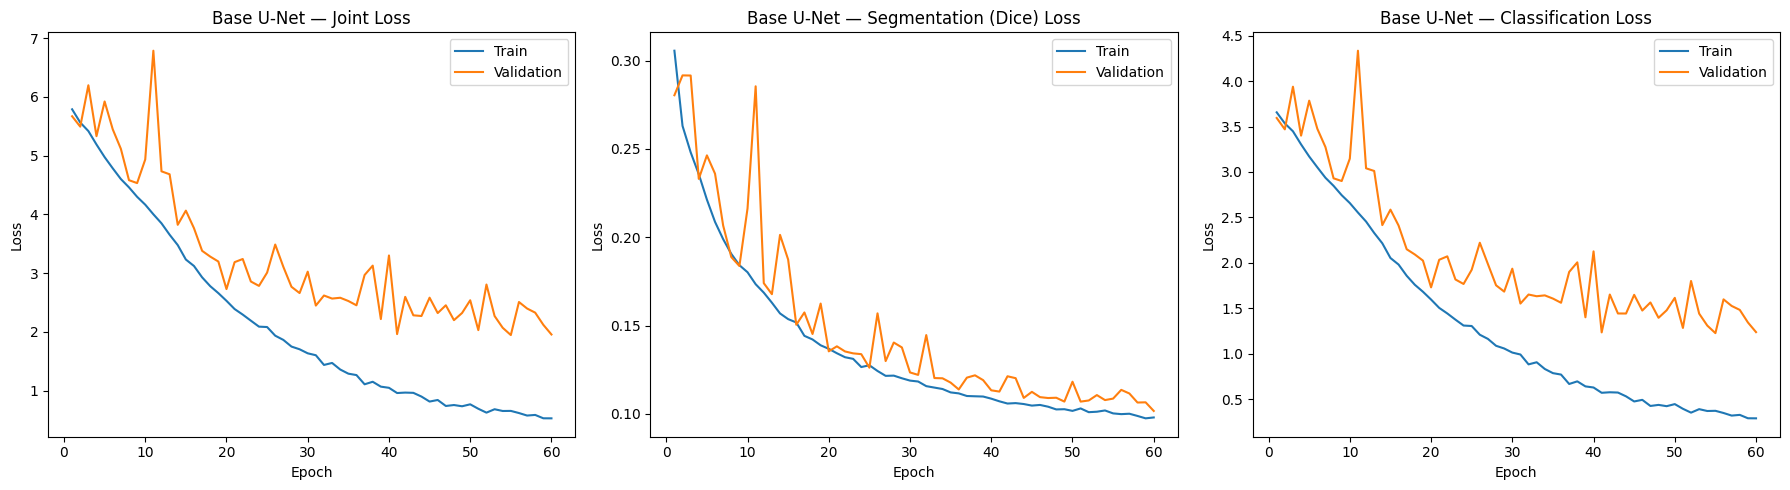

In [ ]:
# ============================================================
# CELL 37: PLOT BASE MODEL TRAINING CURVES
# ============================================================

plot_training_curves(
    train_losses, val_losses,
    train_seg_losses, val_seg_losses,
    train_cls_losses, val_cls_losses,
    title_prefix="Base U-Net —"
)

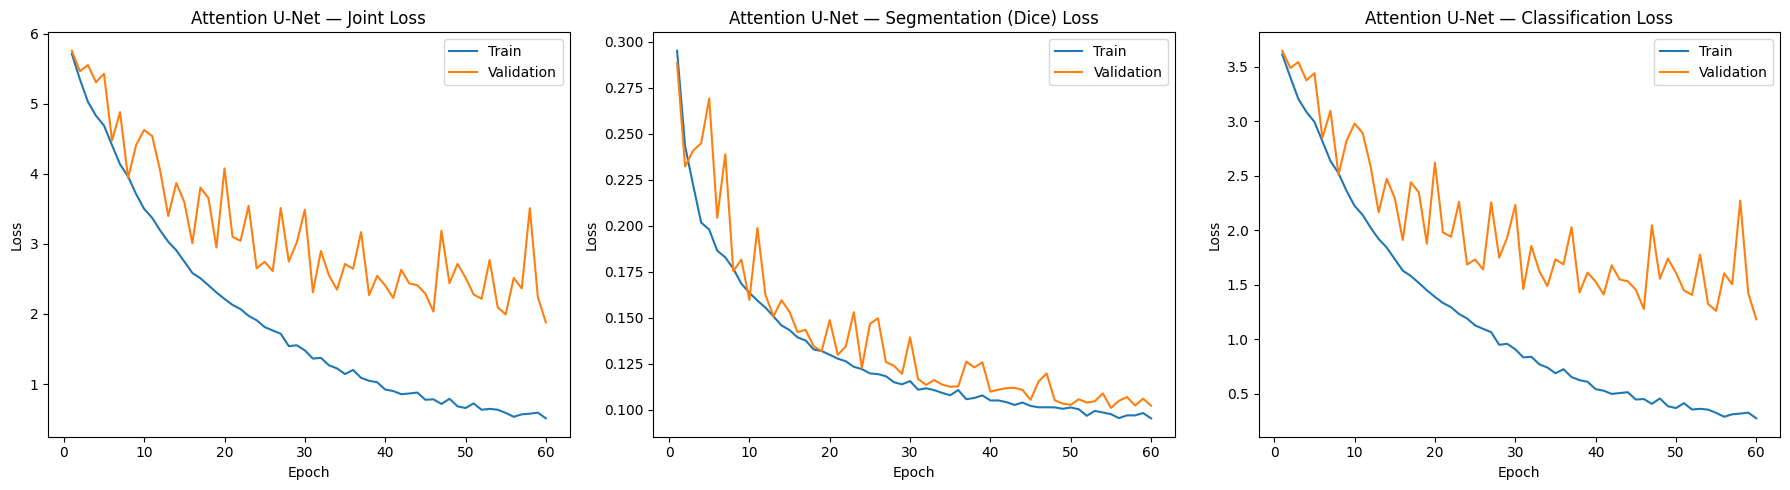

In [ ]:
# ============================================================
# CELL 38: PLOT ATTENTION MODEL TRAINING CURVES
# ============================================================

plot_training_curves(
    attention_train_losses, attention_val_losses,
    attention_train_seg_losses, attention_val_seg_losses,
    attention_train_cls_losses, attention_val_cls_losses,
    title_prefix="Attention U-Net —"
)

In [ ]:
# ============================================================
# CELL 39: SINGLE IMAGE PREDICTION DISPLAY (SIGMOID VERSION)
# ============================================================

def show_prediction(model, dataset, index, device, threshold=0.5):

    model.eval()

    image, true_mask, true_label = dataset[index]

    with torch.no_grad():
        seg_output, cls_output = model(image.unsqueeze(0).to(device))

    probs = torch.sigmoid(seg_output)
    pred_mask = (probs.squeeze(0) > threshold).long().cpu()
    pred_label = torch.argmax(cls_output, dim=1).item()

    true_mask_long = true_mask.long()

    tp = ((pred_mask == 1) & (true_mask_long == 1)).sum().item()
    fp = ((pred_mask == 1) & (true_mask_long == 0)).sum().item()
    fn = ((pred_mask == 0) & (true_mask_long == 1)).sum().item()
    iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0.0

    img_np = image.permute(1, 2, 0).numpy()

    true_breed = idx_to_breed[true_label.item() if hasattr(true_label, "item") else true_label]
    pred_breed = idx_to_breed[pred_label]

    print(f'Original class - "{true_breed}"')
    print(f'Predicted class - "{pred_breed}"')
    print(f"IoU - {iou*100:.1f}%")

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(img_np); axes[0].set_title("Original Image"); axes[0].axis("off")
    axes[1].imshow(img_np); axes[1].imshow(true_mask_long, cmap="Greens", alpha=0.4)
    axes[1].set_title("Image + True Mask Overlay"); axes[1].axis("off")
    axes[2].imshow(img_np); axes[2].imshow(pred_mask, cmap="Greens", alpha=0.4)
    axes[2].set_title("Image + Predicted Mask Overlay"); axes[2].axis("off")

    plt.show()

print("Demo function defined.")

Demo function defined.


===== BASE U-NET =====
Original class - "chihuahua"
Predicted class - "chihuahua"
IoU - 88.1%


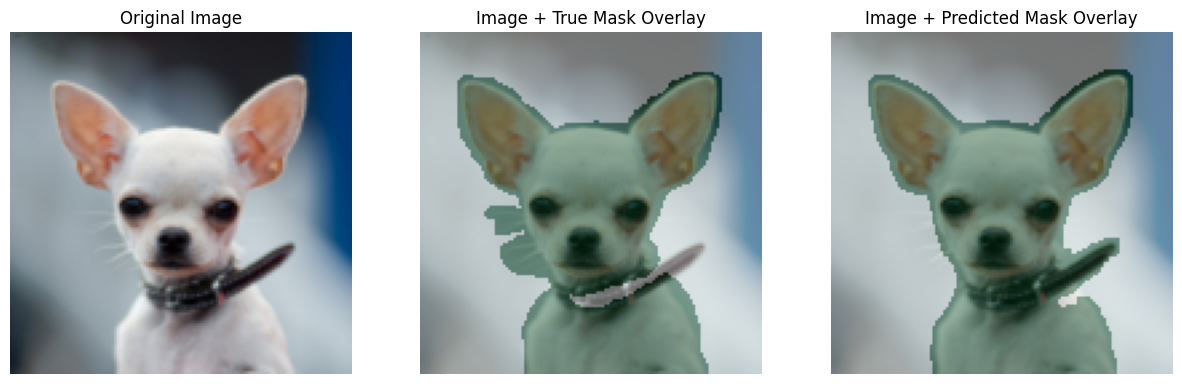


===== ATTENTION U-NET =====
Original class - "chihuahua"
Predicted class - "chihuahua"
IoU - 82.2%


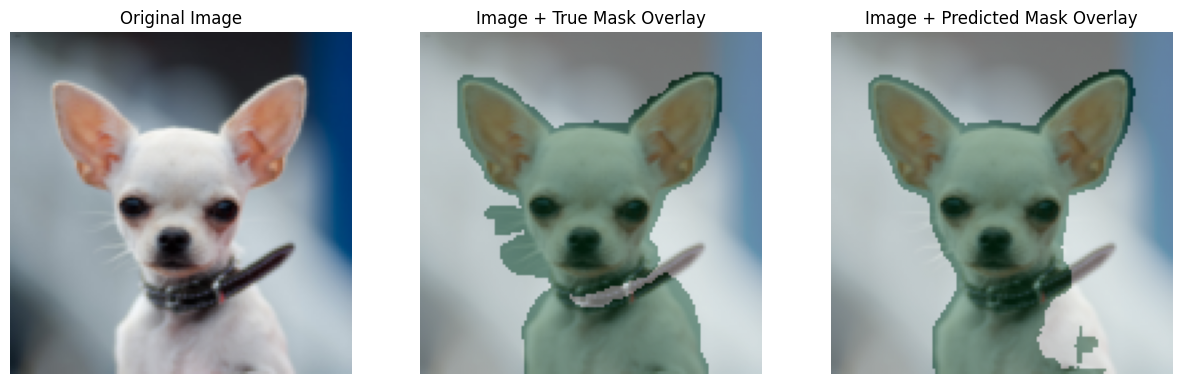

In [ ]:
# ============================================================
# CELL 40: RUN DEMO ON BOTH MODELS
# ============================================================

random_index = random.randint(0, len(test_multitask_dataset) - 1)

print("===== BASE U-NET =====")
show_prediction(multitask_model, test_multitask_dataset, random_index, device)

print("\n===== ATTENTION U-NET =====")
show_prediction(attention_model, test_multitask_dataset, random_index, device)

,Split,Metric,Base U-Net (%),Attention U-Net (%),Δ (Attn - Base)
0,Train,Pixel Accuracy,92.26,92.83,0.57
1,Train,Mean IoU,85.24,86.24,1.00
2,Train,Mean Dice,92.02,92.60,0.58
3,Train,Classification Accuracy,93.27,94.47,1.20
4,Train,Precision (macro),93.67,94.75,1.08
5,Train,Recall (macro),93.23,94.43,1.20
6,Train,F1 (macro),93.23,94.43,1.21
7,Validation,Pixel Accuracy,92.04,92.63,0.59
8,Validation,Mean IoU,84.77,85.80,1.03
9,Validation,Mean Dice,91.74,92.34,0.60



Base U-Net trainable parameters:      45,345,254
Attention U-Net trainable parameters: 45,696,786
Extra parameters from attention gates: 351,532 (0.78% increase)


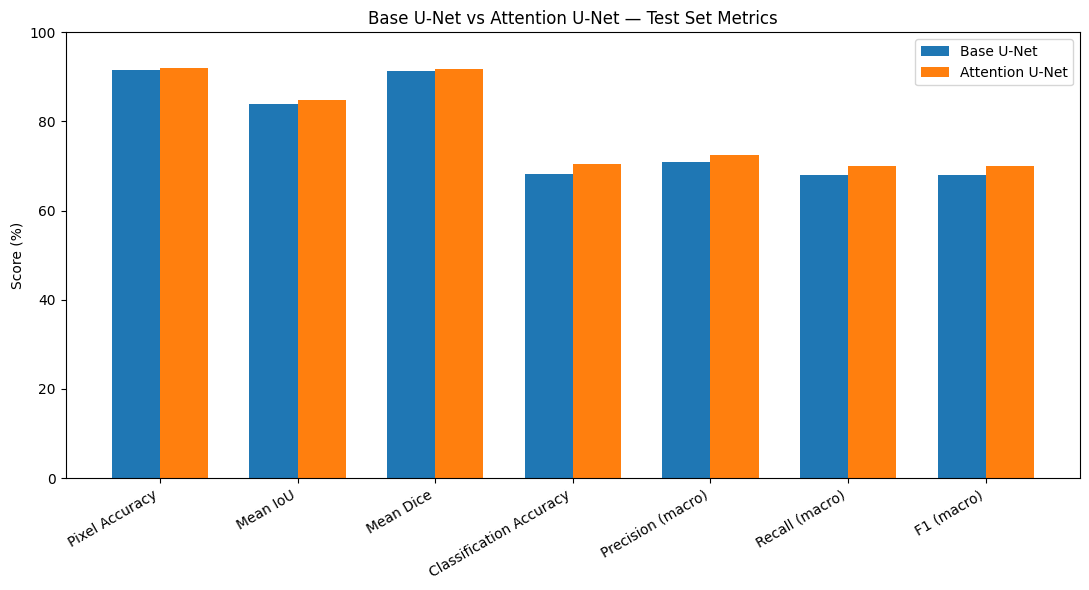

In [ ]:
# ============================================================
# CELL 41: BASE vs ATTENTION U-NET — SIDE-BY-SIDE COMPARISON
# ============================================================

import pandas as pd

def build_comparison_df(base_metrics, attn_metrics, split_name):
    rows = []
    metric_labels = {
        "pixel_acc": "Pixel Accuracy",
        "mIoU": "Mean IoU",
        "dice": "Mean Dice",
        "cls_acc": "Classification Accuracy",
        "precision": "Precision (macro)",
        "recall": "Recall (macro)",
        "f1": "F1 (macro)",
    }
    for key, label in metric_labels.items():
        base_val = base_metrics[key] * 100
        attn_val = attn_metrics[key] * 100
        rows.append({
            "Split": split_name,
            "Metric": label,
            "Base U-Net (%)": round(base_val, 2),
            "Attention U-Net (%)": round(attn_val, 2),
            "Δ (Attn - Base)": round(attn_val - base_val, 2),
        })
    return rows

all_rows = []
all_rows += build_comparison_df(base_train_metrics, attention_train_metrics, "Train")
all_rows += build_comparison_df(base_val_metrics, attention_val_metrics, "Validation")
all_rows += build_comparison_df(base_test_metrics, attention_test_metrics, "Test")

comparison_df = pd.DataFrame(all_rows)
display(comparison_df)

# ---- Parameter count comparison ----
base_params = sum(p.numel() for p in multitask_model.parameters() if p.requires_grad)
attn_params = sum(p.numel() for p in attention_model.parameters() if p.requires_grad)
print(f"\nBase U-Net trainable parameters:      {base_params:,}")
print(f"Attention U-Net trainable parameters: {attn_params:,}")
print(f"Extra parameters from attention gates: {attn_params - base_params:,} "
      f"({(attn_params - base_params) / base_params * 100:.2f}% increase)")

# ---- Bar chart: Test set metrics side by side ----
test_df = comparison_df[comparison_df["Split"] == "Test"].set_index("Metric")

fig, ax = plt.subplots(figsize=(11, 6))
x = range(len(test_df))
width = 0.35

ax.bar([i - width/2 for i in x], test_df["Base U-Net (%)"], width, label="Base U-Net")
ax.bar([i + width/2 for i in x], test_df["Attention U-Net (%)"], width, label="Attention U-Net")

ax.set_xticks(list(x))
ax.set_xticklabels(test_df.index, rotation=30, ha="right")
ax.set_ylabel("Score (%)")
ax.set_title("Base U-Net vs Attention U-Net — Test Set Metrics")
ax.legend()
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

In [ ]:
multitask_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
print("Loaded existing best base model weights.")

multitask_model.classifier.dropout.p = 0.6
print("Dropout increased to 0.6 for the classifier head.")

Loaded existing best base model weights.
Dropout increased to 0.6 for the classifier head.


In [ ]:
finetune_optimizer = optim.Adam(multitask_model.parameters(), lr=0.0001, weight_decay=3e-4)

segmentation_criterion = DiceLoss()
classification_criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

FINETUNE_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 5
epochs_without_improvement = 0

best_val_cls_loss = float("inf")
finetune_val_cls_losses = []

BEST_FINETUNED_PATH = os.path.join(CHECKPOINT_DIR, "best_finetuned_base_unet.pth")

print("Fine-tuning setup ready.")

Fine-tuning setup ready.


In [ ]:
for epoch in range(FINETUNE_EPOCHS):

    print(f"\nFine-tune Epoch [{epoch + 1}/{FINETUNE_EPOCHS}]")

    train_loss, train_seg_loss, train_cls_loss = train_one_epoch(
        multitask_model, train_multitask_loader, finetune_optimizer,
        segmentation_criterion, classification_criterion, device,
        seg_weight=1.0, cls_weight=1.5
    )

    val_loss, val_seg_loss, val_cls_loss = validate_one_epoch(
        multitask_model, val_multitask_loader,
        segmentation_criterion, classification_criterion, device,
        seg_weight=1.0, cls_weight=1.5
    )

    finetune_val_cls_losses.append(val_cls_loss)

    print(f"Train Cls Loss: {train_cls_loss:.4f} | Val Cls Loss: {val_cls_loss:.4f}")
    print(f"Val Seg Loss: {val_seg_loss:.4f}")

    if val_cls_loss < best_val_cls_loss:
        best_val_cls_loss = val_cls_loss
        torch.save(multitask_model.state_dict(), BEST_FINETUNED_PATH)
        print("✓ Improved — saved fine-tuned model.")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping — no improvement for {EARLY_STOPPING_PATIENCE} epochs.")
        break

print("\nFine-tuning complete!")


Fine-tune Epoch [1/15]
Train Cls Loss: 1.6554 | Val Cls Loss: 2.0802
Val Seg Loss: 0.0960
✓ Improved — saved fine-tuned model.

Fine-tune Epoch [2/15]
Train Cls Loss: 1.4920 | Val Cls Loss: 1.9285
Val Seg Loss: 0.0936
✓ Improved — saved fine-tuned model.

Fine-tune Epoch [3/15]
Train Cls Loss: 1.3776 | Val Cls Loss: 1.7531
Val Seg Loss: 0.0929
✓ Improved — saved fine-tuned model.

Fine-tune Epoch [4/15]
Train Cls Loss: 1.3035 | Val Cls Loss: 1.6685
Val Seg Loss: 0.0933
✓ Improved — saved fine-tuned model.

Fine-tune Epoch [5/15]
Train Cls Loss: 1.2321 | Val Cls Loss: 1.6158
Val Seg Loss: 0.0937
✓ Improved — saved fine-tuned model.

Fine-tune Epoch [6/15]
Train Cls Loss: 1.1904 | Val Cls Loss: 1.5873
Val Seg Loss: 0.0932
✓ Improved — saved fine-tuned model.

Fine-tune Epoch [7/15]
Train Cls Loss: 1.1488 | Val Cls Loss: 1.5310
Val Seg Loss: 0.0916
✓ Improved — saved fine-tuned model.

Fine-tune Epoch [8/15]
Train Cls Loss: 1.1320 | Val Cls Loss: 1.5629
Val Seg Loss: 0.0917

Fine-tune Ep

In [ ]:
multitask_model.load_state_dict(torch.load(BEST_FINETUNED_PATH, map_location=device))

print(">>> FINE-TUNED BASE MODEL")
finetuned_test_metrics = evaluate_multitask_model(multitask_model, test_multitask_loader, device, "Test")

print("\n(Compare against your original test cls accuracy: 68.26%)")

>>> FINE-TUNED BASE MODEL
===== Test SET RESULTS =====
Pixel Accuracy: 93.08%
Mean IoU: 86.82%
Mean Dice: 92.94%
Classification Accuracy: 78.00%
Precision (macro): 78.32%
Recall (macro): 77.99%
F1 (macro): 77.87%


(Compare against your original test cls accuracy: 68.26%)


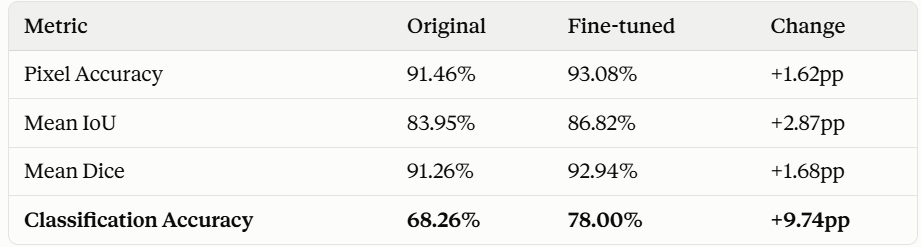

In [ ]:
attention_model.load_state_dict(torch.load(ATTENTION_BEST_MODEL_PATH, map_location=device))
print("Loaded existing best attention model weights.")

attention_model.classifier.dropout.p = 0.6
print("Dropout increased to 0.6 for the classifier head.")

Loaded existing best attention model weights.
Dropout increased to 0.6 for the classifier head.


In [ ]:
attention_finetune_optimizer = optim.Adam(attention_model.parameters(), lr=0.0001, weight_decay=3e-4)

attention_segmentation_criterion = DiceLoss()
attention_classification_criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

ATTENTION_FINETUNE_EPOCHS = 15
ATTENTION_EARLY_STOPPING_PATIENCE = 5
attention_epochs_without_improvement = 0

attention_best_val_cls_loss = float("inf")
attention_finetune_val_cls_losses = []

BEST_FINETUNED_ATTENTION_PATH = os.path.join(CHECKPOINT_DIR, "best_finetuned_attention_unet.pth")

print("Attention fine-tuning setup ready.")

Attention fine-tuning setup ready.


In [ ]:
for epoch in range(ATTENTION_FINETUNE_EPOCHS):

    print(f"\nFine-tune Epoch [{epoch + 1}/{ATTENTION_FINETUNE_EPOCHS}]")

    train_loss, train_seg_loss, train_cls_loss = train_one_epoch(
        attention_model, train_multitask_loader, attention_finetune_optimizer,
        attention_segmentation_criterion, attention_classification_criterion, device,
        seg_weight=1.0, cls_weight=1.5
    )

    val_loss, val_seg_loss, val_cls_loss = validate_one_epoch(
        attention_model, val_multitask_loader,
        attention_segmentation_criterion, attention_classification_criterion, device,
        seg_weight=1.0, cls_weight=1.5
    )

    attention_finetune_val_cls_losses.append(val_cls_loss)

    print(f"Train Cls Loss: {train_cls_loss:.4f} | Val Cls Loss: {val_cls_loss:.4f}")
    print(f"Val Seg Loss: {val_seg_loss:.4f}")

    if val_cls_loss < attention_best_val_cls_loss:
        attention_best_val_cls_loss = val_cls_loss
        torch.save(attention_model.state_dict(), BEST_FINETUNED_ATTENTION_PATH)
        print("✓ Improved — saved fine-tuned attention model.")
        attention_epochs_without_improvement = 0
    else:
        attention_epochs_without_improvement += 1

    if attention_epochs_without_improvement >= ATTENTION_EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping — no improvement for {ATTENTION_EARLY_STOPPING_PATIENCE} epochs.")
        break

print("\nAttention fine-tuning complete!")


Fine-tune Epoch [1/15]
Train Cls Loss: 1.6857 | Val Cls Loss: 2.1367
Val Seg Loss: 0.0933
✓ Improved — saved fine-tuned attention model.

Fine-tune Epoch [2/15]
Train Cls Loss: 1.5185 | Val Cls Loss: 1.9630
Val Seg Loss: 0.0917
✓ Improved — saved fine-tuned attention model.

Fine-tune Epoch [3/15]
Train Cls Loss: 1.3897 | Val Cls Loss: 1.7617
Val Seg Loss: 0.0900
✓ Improved — saved fine-tuned attention model.

Fine-tune Epoch [4/15]
Train Cls Loss: 1.2856 | Val Cls Loss: 1.6158
Val Seg Loss: 0.0888
✓ Improved — saved fine-tuned attention model.

Fine-tune Epoch [5/15]
Train Cls Loss: 1.2066 | Val Cls Loss: 1.5411
Val Seg Loss: 0.0886
✓ Improved — saved fine-tuned attention model.

Fine-tune Epoch [6/15]
Train Cls Loss: 1.1721 | Val Cls Loss: 1.4893
Val Seg Loss: 0.0881
✓ Improved — saved fine-tuned attention model.

Fine-tune Epoch [7/15]
Train Cls Loss: 1.1264 | Val Cls Loss: 1.4623
Val Seg Loss: 0.0875
✓ Improved — saved fine-tuned attention model.

Fine-tune Epoch [8/15]
Train Cls 

In [ ]:
attention_model.load_state_dict(torch.load(BEST_FINETUNED_ATTENTION_PATH, map_location=device))

print(">>> FINE-TUNED ATTENTION MODEL")
finetuned_attention_test_metrics = evaluate_multitask_model(attention_model, test_multitask_loader, device, "Test")

print("\n(Compare against original attention test cls accuracy: 70.42%)")

>>> FINE-TUNED ATTENTION MODEL
===== Test SET RESULTS =====
Pixel Accuracy: 93.24%
Mean IoU: 87.09%
Mean Dice: 93.09%
Classification Accuracy: 75.56%
Precision (macro): 76.13%
Recall (macro): 75.78%
F1 (macro): 75.48%


(Compare against original attention test cls accuracy: 70.42%)


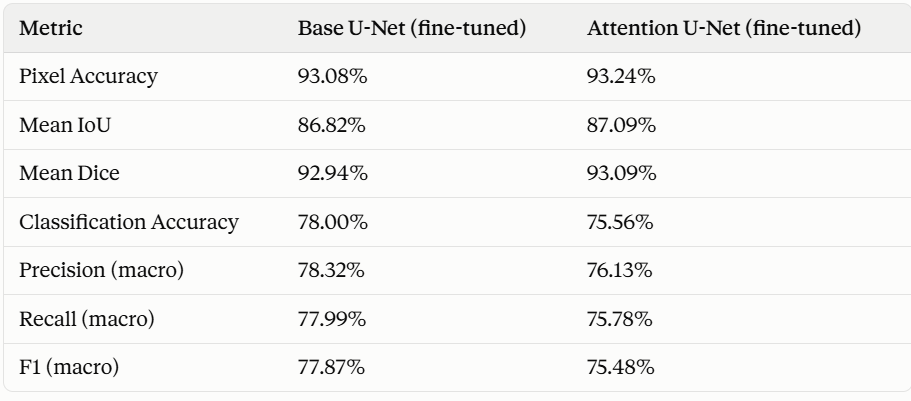

In [ ]:
import shutil

shutil.copy(BEST_FINETUNED_PATH, BEST_MODEL_PATH)
shutil.copy(BEST_FINETUNED_ATTENTION_PATH, ATTENTION_BEST_MODEL_PATH)

print("Fine-tuned weights are now the official best checkpoints.")
print("Your demo notebook will automatically use these on next load.")

Fine-tuned weights are now the official best checkpoints.
Your demo notebook will automatically use these on next load.


>>> FINAL BASE U-NET (fine-tuned)
===== Test SET RESULTS =====
Pixel Accuracy: 93.08%
Mean IoU: 86.82%
Mean Dice: 92.94%
Classification Accuracy: 78.00%
Precision (macro): 78.32%
Recall (macro): 77.99%
F1 (macro): 77.87%

>>> FINAL ATTENTION U-NET (fine-tuned)
===== Test SET RESULTS =====
Pixel Accuracy: 93.24%
Mean IoU: 87.09%
Mean Dice: 93.09%
Classification Accuracy: 75.56%
Precision (macro): 76.13%
Recall (macro): 75.78%
F1 (macro): 75.48%



,Classifier,Test Accuracy (%),Precision (%),Recall (%),F1 (%)
0,"Base U-Net (joint head, fine-tuned)",78.00,78.32,77.99,77.87
1,"Attention U-Net (joint head, fine-tuned)",75.56,76.13,75.78,75.48
2,MobileNetV2,91.70,91.81,91.90,91.76
3,EfficientNet-B0,93.42,93.57,93.58,93.47
4,DenseNet121,92.61,93.03,92.66,92.44


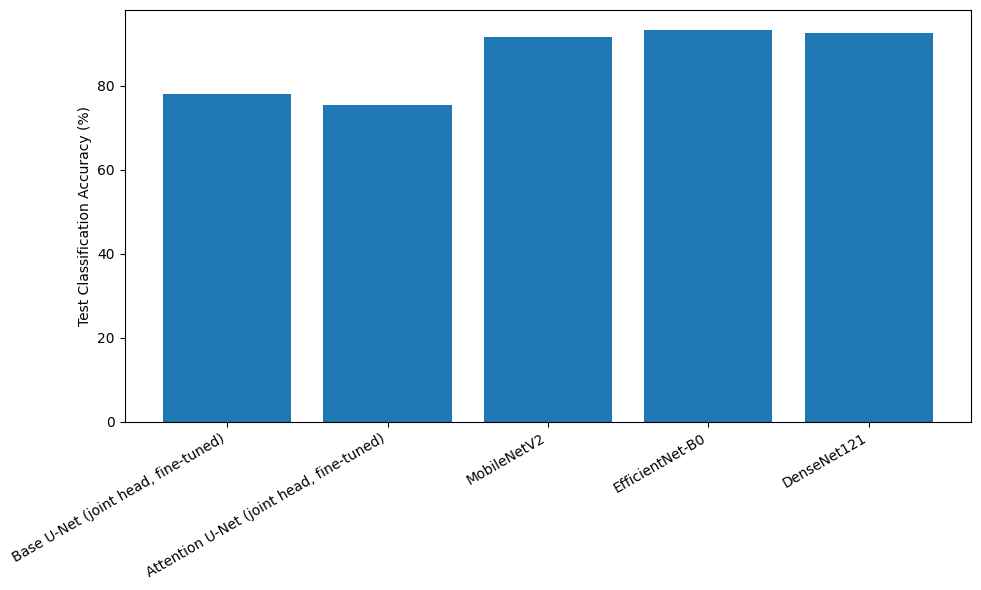

In [ ]:
# ============================================================
# CELL 49: FINAL RESULTS — FINE-TUNED MODELS (OFFICIAL NUMBERS)
# ============================================================

multitask_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
attention_model.load_state_dict(torch.load(ATTENTION_BEST_MODEL_PATH, map_location=device))

print(">>> FINAL BASE U-NET (fine-tuned)")
base_test_metrics = evaluate_multitask_model(multitask_model, test_multitask_loader, device, "Test")

print(">>> FINAL ATTENTION U-NET (fine-tuned)")
attention_test_metrics = evaluate_multitask_model(attention_model, test_multitask_loader, device, "Test")

# Rebuild the bonus comparison table with corrected numbers
rows = [
    {"Classifier": "Base U-Net (joint head, fine-tuned)",
     "Test Accuracy (%)": base_test_metrics["cls_acc"] * 100,
     "Precision (%)": base_test_metrics["precision"] * 100,
     "Recall (%)": base_test_metrics["recall"] * 100,
     "F1 (%)": base_test_metrics["f1"] * 100},
    {"Classifier": "Attention U-Net (joint head, fine-tuned)",
     "Test Accuracy (%)": attention_test_metrics["cls_acc"] * 100,
     "Precision (%)": attention_test_metrics["precision"] * 100,
     "Recall (%)": attention_test_metrics["recall"] * 100,
     "F1 (%)": attention_test_metrics["f1"] * 100},
]
for arch_name, results in bonus_results.items():
    t = results["test"]
    rows.append({"Classifier": display_names[arch_name],
                  "Test Accuracy (%)": t["cls_acc"] * 100,
                  "Precision (%)": t["precision"] * 100,
                  "Recall (%)": t["recall"] * 100,
                  "F1 (%)": t["f1"] * 100})

final_comparison_df = pd.DataFrame(rows).round(2)
display(final_comparison_df)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(final_comparison_df["Classifier"], final_comparison_df["Test Accuracy (%)"], color="tab:blue")
ax.set_ylabel("Test Classification Accuracy (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 42: BONUS 1 — SETUP FOR PRETRAINED BACKBONE COMPARISON
# ============================================================

from torchvision import models
import pandas as pd

BONUS_IMG_SIZE = 224   # standard input size these pretrained backbones expect
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

BONUS_CHECKPOINT_DIR = os.path.join(CHECKPOINT_DIR, "bonus_classifiers")
os.makedirs(BONUS_CHECKPOINT_DIR, exist_ok=True)

print("Bonus Task 1 setup ready.")

Bonus Task 1 setup ready.


In [ ]:
# ============================================================
# CELL 43: CLASSIFICATION-ONLY DATASET (IMAGE + BREED LABEL)
# ============================================================

class BreedClassificationDataset(Dataset):
    def __init__(self, image_paths, breed_to_idx, img_size=224, augment=False):
        self.image_paths = image_paths
        self.breed_to_idx = breed_to_idx
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")
        image = image.resize((self.img_size, self.img_size), Image.Resampling.BILINEAR)

        if self.augment:
            if pyrandom.random() < 0.5:
                image = TF.hflip(image)
            if pyrandom.random() < 0.3:
                angle = pyrandom.uniform(-15, 15)
                image = TF.rotate(image, angle, interpolation=TF.InterpolationMode.BILINEAR)
            if pyrandom.random() < 0.3:
                image = TF.adjust_brightness(image, pyrandom.uniform(0.8, 1.2))
                image = TF.adjust_contrast(image, pyrandom.uniform(0.8, 1.2))

        image = TF.to_tensor(image)
        image = TF.normalize(image, mean=IMAGENET_MEAN, std=IMAGENET_STD)  # required for pretrained weights

        breed = get_breed_name(self.image_paths[index])
        label = torch.tensor(self.breed_to_idx[breed], dtype=torch.long)

        return image, label

train_cls_dataset = BreedClassificationDataset(train_image_paths, breed_to_idx, img_size=BONUS_IMG_SIZE, augment=True)
val_cls_dataset   = BreedClassificationDataset(val_image_paths, breed_to_idx, img_size=BONUS_IMG_SIZE, augment=False)
test_cls_dataset  = BreedClassificationDataset(test_image_paths, breed_to_idx, img_size=BONUS_IMG_SIZE, augment=False)

train_cls_loader = DataLoader(train_cls_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_cls_loader   = DataLoader(val_cls_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_cls_loader  = DataLoader(test_cls_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print("Train:", len(train_cls_dataset), "Val:", len(val_cls_dataset), "Test:", len(test_cls_dataset))

Train: 5173 Val: 1108 Test: 1109


In [ ]:
# ============================================================
# CELL 44: PRETRAINED CLASSIFIER FACTORY (MobileNetV2 / EfficientNet-B0 / DenseNet121)
# ============================================================

def build_pretrained_classifier(arch_name, num_classes=37):
    if arch_name == "mobilenet_v2":
        model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    elif arch_name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    elif arch_name == "densenet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)

    else:
        raise ValueError(f"Unknown architecture: {arch_name}")

    return model

print("Pretrained classifier factory defined.")

Pretrained classifier factory defined.


In [ ]:
# ============================================================
# CELL 45: TRAIN / VALIDATE FUNCTIONS (CLASSIFICATION-ONLY)
# ============================================================

def train_classifier_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    return running_loss / len(loader)


def validate_classifier_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            running_loss += criterion(model(images), labels).item()
    return running_loss / len(loader)

print("Classifier train/validate functions defined.")

Classifier train/validate functions defined.


In [ ]:
# ============================================================
# CELL 46: TRAIN ALL THREE BACKBONES (RESUMABLE, FINE-TUNED)
# ============================================================

BACKBONE_NAMES = ["mobilenet_v2", "efficientnet_b0", "densenet121"]
BONUS_NUM_EPOCHS = 15   # pretrained weights need far fewer epochs than training from scratch

bonus_models = {}
bonus_histories = {}

for arch_name in BACKBONE_NAMES:
    print(f"\n{'='*60}\nTraining backbone: {arch_name}\n{'='*60}")

    model = build_pretrained_classifier(arch_name, num_classes=37).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)  # lower LR: fine-tuning, not training from scratch
    criterion = nn.CrossEntropyLoss()

    best_path = os.path.join(BONUS_CHECKPOINT_DIR, f"best_{arch_name}.pth")
    resume_path = os.path.join(BONUS_CHECKPOINT_DIR, f"resume_{arch_name}.pth")

    train_losses, val_losses = [], []
    start_epoch = 0
    best_val_loss = float("inf")

    if os.path.exists(resume_path):
        checkpoint = torch.load(resume_path, map_location=device)
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        start_epoch = checkpoint["epoch"]
        train_losses = checkpoint["history"]["train_losses"]
        val_losses = checkpoint["history"]["val_losses"]
        best_val_loss = min(val_losses) if val_losses else float("inf")
        print(f"Resuming {arch_name} from epoch {start_epoch + 1}")

    for epoch in range(start_epoch, BONUS_NUM_EPOCHS):
        train_loss = train_classifier_one_epoch(model, train_cls_loader, optimizer, criterion, device)
        val_loss = validate_classifier_one_epoch(model, val_cls_loader, criterion, device)
        train_losses.append(train_loss); val_losses.append(val_loss)

        print(f"[{arch_name}] Epoch [{epoch+1}/{BONUS_NUM_EPOCHS}] Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), best_path)

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": {"train_losses": train_losses, "val_losses": val_losses}
        }, resume_path)

    model.load_state_dict(torch.load(best_path, map_location=device))
    bonus_models[arch_name] = model
    bonus_histories[arch_name] = {"train_losses": train_losses, "val_losses": val_losses}

print("\nAll backbone models trained.")


Training backbone: mobilenet_v2
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 63.5MB/s]


[mobilenet_v2] Epoch [1/15] Train Loss: 2.4371 | Val Loss: 1.1095
[mobilenet_v2] Epoch [2/15] Train Loss: 0.8240 | Val Loss: 0.4988
[mobilenet_v2] Epoch [3/15] Train Loss: 0.4624 | Val Loss: 0.3484
[mobilenet_v2] Epoch [4/15] Train Loss: 0.3055 | Val Loss: 0.2937
[mobilenet_v2] Epoch [5/15] Train Loss: 0.2330 | Val Loss: 0.2682
[mobilenet_v2] Epoch [6/15] Train Loss: 0.1713 | Val Loss: 0.2528
[mobilenet_v2] Epoch [7/15] Train Loss: 0.1239 | Val Loss: 0.2492
[mobilenet_v2] Epoch [8/15] Train Loss: 0.0912 | Val Loss: 0.2478
[mobilenet_v2] Epoch [9/15] Train Loss: 0.0773 | Val Loss: 0.2649
[mobilenet_v2] Epoch [10/15] Train Loss: 0.0646 | Val Loss: 0.2539
[mobilenet_v2] Epoch [11/15] Train Loss: 0.0555 | Val Loss: 0.2442
[mobilenet_v2] Epoch [12/15] Train Loss: 0.0471 | Val Loss: 0.2618
[mobilenet_v2] Epoch [13/15] Train Loss: 0.0404 | Val Loss: 0.2453
[mobilenet_v2] Epoch [14/15] Train Loss: 0.0351 | Val Loss: 0.2401
[mobilenet_v2] Epoch [15/15] Train Loss: 0.0271 | Val Loss: 0.2375

Tra

100%|██████████| 20.5M/20.5M [00:00<00:00, 142MB/s]


[efficientnet_b0] Epoch [1/15] Train Loss: 2.3738 | Val Loss: 0.8982
[efficientnet_b0] Epoch [2/15] Train Loss: 0.7217 | Val Loss: 0.3828
[efficientnet_b0] Epoch [3/15] Train Loss: 0.3802 | Val Loss: 0.2683
[efficientnet_b0] Epoch [4/15] Train Loss: 0.2551 | Val Loss: 0.2330
[efficientnet_b0] Epoch [5/15] Train Loss: 0.1813 | Val Loss: 0.2013
[efficientnet_b0] Epoch [6/15] Train Loss: 0.1370 | Val Loss: 0.2057
[efficientnet_b0] Epoch [7/15] Train Loss: 0.1056 | Val Loss: 0.2052
[efficientnet_b0] Epoch [8/15] Train Loss: 0.0818 | Val Loss: 0.1913
[efficientnet_b0] Epoch [9/15] Train Loss: 0.0677 | Val Loss: 0.2031
[efficientnet_b0] Epoch [10/15] Train Loss: 0.0597 | Val Loss: 0.1943
[efficientnet_b0] Epoch [11/15] Train Loss: 0.0514 | Val Loss: 0.1983
[efficientnet_b0] Epoch [12/15] Train Loss: 0.0449 | Val Loss: 0.2032
[efficientnet_b0] Epoch [13/15] Train Loss: 0.0435 | Val Loss: 0.2099
[efficientnet_b0] Epoch [14/15] Train Loss: 0.0408 | Val Loss: 0.1939
[efficientnet_b0] Epoch [15/1

100%|██████████| 30.8M/30.8M [00:00<00:00, 173MB/s]


[densenet121] Epoch [1/15] Train Loss: 1.6371 | Val Loss: 0.5987
[densenet121] Epoch [2/15] Train Loss: 0.4309 | Val Loss: 0.3250
[densenet121] Epoch [3/15] Train Loss: 0.2260 | Val Loss: 0.3447
[densenet121] Epoch [4/15] Train Loss: 0.1482 | Val Loss: 0.2920
[densenet121] Epoch [5/15] Train Loss: 0.1033 | Val Loss: 0.2858
[densenet121] Epoch [6/15] Train Loss: 0.0756 | Val Loss: 0.3332
[densenet121] Epoch [7/15] Train Loss: 0.0665 | Val Loss: 0.2890
[densenet121] Epoch [8/15] Train Loss: 0.0473 | Val Loss: 0.2838
[densenet121] Epoch [9/15] Train Loss: 0.0419 | Val Loss: 0.2666
[densenet121] Epoch [10/15] Train Loss: 0.0527 | Val Loss: 0.3024
[densenet121] Epoch [11/15] Train Loss: 0.0433 | Val Loss: 0.2679
[densenet121] Epoch [12/15] Train Loss: 0.0461 | Val Loss: 0.3426
[densenet121] Epoch [13/15] Train Loss: 0.0402 | Val Loss: 0.2912
[densenet121] Epoch [14/15] Train Loss: 0.0364 | Val Loss: 0.3295
[densenet121] Epoch [15/15] Train Loss: 0.0340 | Val Loss: 0.3071

All backbone model

In [ ]:
# ============================================================
# CELL 47: EVALUATE EACH BACKBONE (ACC / PRECISION / RECALL / F1)
# ============================================================

def evaluate_classifier(model, loader, device):
    model.eval()
    all_true, all_pred = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            preds = torch.argmax(model(images), dim=1).cpu().numpy()
            all_true.extend(labels.numpy())
            all_pred.extend(preds)

    return {
        "cls_acc": accuracy_score(all_true, all_pred),
        "precision": precision_score(all_true, all_pred, average="macro", zero_division=0),
        "recall": recall_score(all_true, all_pred, average="macro", zero_division=0),
        "f1": f1_score(all_true, all_pred, average="macro", zero_division=0),
    }

bonus_results = {}
for arch_name, model in bonus_models.items():
    bonus_results[arch_name] = {
        "train": evaluate_classifier(model, train_cls_loader, device),
        "val": evaluate_classifier(model, val_cls_loader, device),
        "test": evaluate_classifier(model, test_cls_loader, device),
    }
    print(f"{arch_name} — Test Accuracy: {bonus_results[arch_name]['test']['cls_acc']*100:.2f}%")

mobilenet_v2 — Test Accuracy: 91.70%
efficientnet_b0 — Test Accuracy: 93.42%
densenet121 — Test Accuracy: 92.61%


,Classifier,Test Accuracy (%),Precision (%),Recall (%),F1 (%)
0,Base U-Net (joint head),68.26,70.91,68.01,68.00
1,Attention U-Net (joint head),70.42,72.43,70.12,70.01
2,MobileNetV2,91.70,91.81,91.90,91.76
3,EfficientNet-B0,93.42,93.57,93.58,93.47
4,DenseNet121,92.61,93.03,92.66,92.44


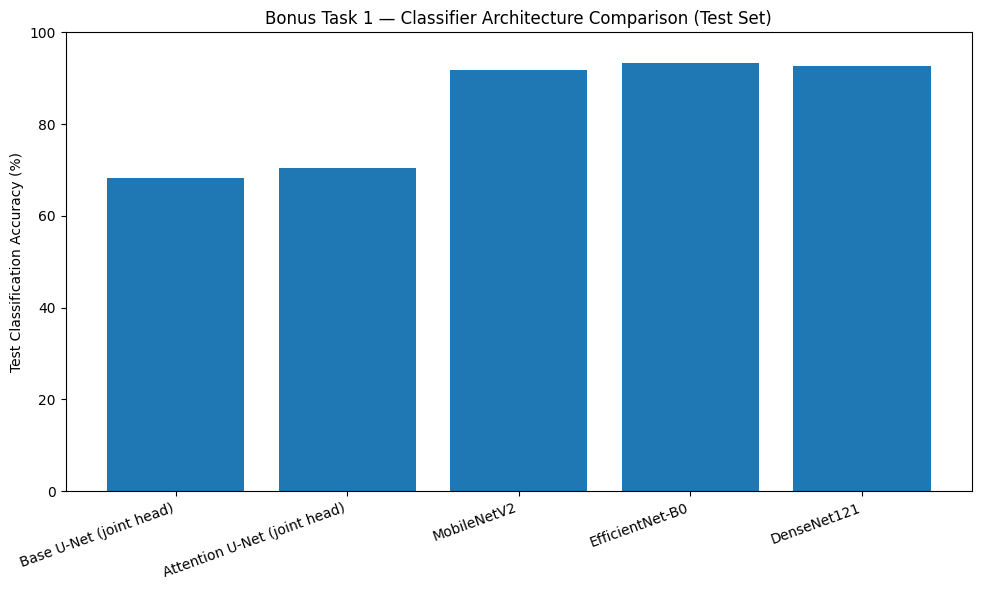

In [ ]:
# ============================================================
# CELL 48: BONUS TASK 1 — FULL COMPARISON (JOINT HEADS + BACKBONES)
# ============================================================

display_names = {"mobilenet_v2": "MobileNetV2", "efficientnet_b0": "EfficientNet-B0", "densenet121": "DenseNet121"}

rows = [
    {"Classifier": "Base U-Net (joint head)",
     "Test Accuracy (%)": base_test_metrics["cls_acc"] * 100,
     "Precision (%)": base_test_metrics["precision"] * 100,
     "Recall (%)": base_test_metrics["recall"] * 100,
     "F1 (%)": base_test_metrics["f1"] * 100},
    {"Classifier": "Attention U-Net (joint head)",
     "Test Accuracy (%)": attention_test_metrics["cls_acc"] * 100,
     "Precision (%)": attention_test_metrics["precision"] * 100,
     "Recall (%)": attention_test_metrics["recall"] * 100,
     "F1 (%)": attention_test_metrics["f1"] * 100},
]
for arch_name, results in bonus_results.items():
    t = results["test"]
    rows.append({"Classifier": display_names[arch_name],
                  "Test Accuracy (%)": t["cls_acc"] * 100,
                  "Precision (%)": t["precision"] * 100,
                  "Recall (%)": t["recall"] * 100,
                  "F1 (%)": t["f1"] * 100})

bonus_comparison_df = pd.DataFrame(rows).round(2)
display(bonus_comparison_df)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(bonus_comparison_df["Classifier"], bonus_comparison_df["Test Accuracy (%)"], color="tab:blue")
ax.set_ylabel("Test Classification Accuracy (%)")
ax.set_title("Bonus Task 1 — Classifier Architecture Comparison (Test Set)")
ax.set_ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# SAVE DEMO ASSETS (RUN IN TRAINING NOTEBOOK)
# ============================================================

import json

DEMO_ASSETS_PATH = os.path.join(PROJECT_PATH, "..", "demo_assets_v2")
DEMO_ASSETS_PATH = os.path.abspath(DEMO_ASSETS_PATH)
os.makedirs(DEMO_ASSETS_PATH, exist_ok=True)

# Your checkpoints are already in CHECKPOINT_DIR on Drive, just confirm paths
print("Base model checkpoint exists:", os.path.exists(BEST_MODEL_PATH))
print("Attention model checkpoint exists:", os.path.exists(ATTENTION_BEST_MODEL_PATH))

with open(os.path.join(DEMO_ASSETS_PATH, "breed_to_idx.json"), "w") as f:
    json.dump(breed_to_idx, f)

print("Breed mapping saved to:", DEMO_ASSETS_PATH)
print("Demo assets folder contents:", os.listdir(DEMO_ASSETS_PATH))

Base model checkpoint exists: True
Attention model checkpoint exists: True
Breed mapping saved to: /content/demo_assets_v2
Demo assets folder contents: ['breed_to_idx.json']


In [ ]:
# ============================================================
# SAVE DEMO ASSETS (CORRECTED - EXPLICIT DRIVE PATH)
# ============================================================

import json

DRIVE_PROJECT_PATH = "/content/drive/MyDrive/CSE428_Project"
DEMO_ASSETS_PATH = os.path.join(DRIVE_PROJECT_PATH, "demo_assets_v2")
os.makedirs(DEMO_ASSETS_PATH, exist_ok=True)

with open(os.path.join(DEMO_ASSETS_PATH, "breed_to_idx.json"), "w") as f:
    json.dump(breed_to_idx, f)

print("Saved to:", DEMO_ASSETS_PATH)
print("Contents:", os.listdir(DEMO_ASSETS_PATH))

Saved to: /content/drive/MyDrive/CSE428_Project/demo_assets_v2
Contents: ['breed_to_idx.json']
